# Prepare the 2D field for the browser turtle

I load the saved 256² field and convert c≥0.5 into a phase mask. c is dimensionless composition. The transpose and reversal match the screen coordinates. I save a JSON array of occupied pixels, not a predefined turtle route.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## A visual story before the code

Can I follow a route without leaving the phase?

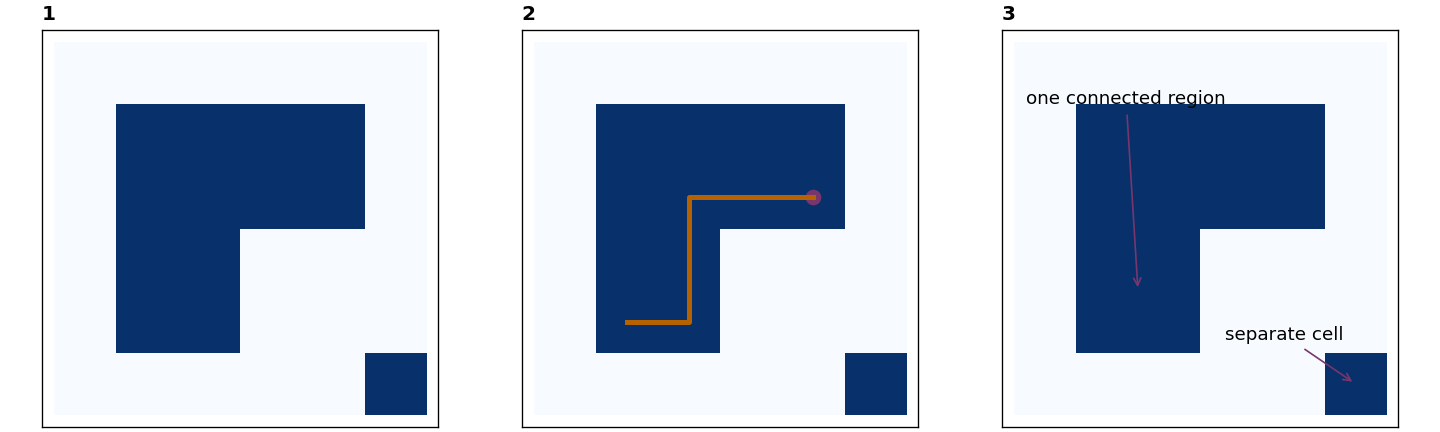

**Panel 1: Choose the allowed region.** Which cells may the turtle enter? A binary mask separates allowed and forbidden cells.

**Panel 2: Follow neighboring occupied cells.** Every step needs a valid connection. The route in the drawing stays inside one edge-connected group. A visual jump would not establish a path.

**Panel 3: Distinguish an address from a journey.** Wrapping the display is not the same as closing a route. For a periodic field, the code keeps wrapped addresses and unwrapped route information. The notebook prepares or validates that data before an optional viewer displays it.

These drawings explain the ideas. They are not numerical output from this notebook. I then follow the code, its recorded results and its checks.


## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Read the saved composition

I use the original saved 256² field. I check its dimensions and mean before applying a threshold.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

work = Path("lesson-data")
work.mkdir(exist_ok=True)

def get_file(relative_path):
    # I download a public example only when its local copy is missing.
    destination = work / Path(relative_path).name
    if not destination.exists():
        urlretrieve("https://saswataiith.github.io/" + relative_path, destination)
    return destination

field_path = get_file("assets/examples/bicontinuity/composition-0.5.npy")
output_path = work / "turtle-field.json"

<details>
<summary>Implementation checks</summary>

## Step 3: My check of this result

I check finite values, conservation or the known reference result as specified below. An assertion stops the notebook if the condition fails. Inspect the quantities and tolerance rather than suppressing a failure.

</details>

In [3]:
from pathlib import Path
import json
import sys
import numpy as np
composition = np.load(field_path)
assert composition.shape == (256, 256)
assert abs(composition.mean() - 0.5) < 1e-10
screen_field = composition.T[::-1]
result = {'size': 256, 'mean': float(composition.mean()), 'threshold': 0.5, 'source': 'bicontinuity.py, seed 20260921, time 400', 'mask': (screen_field >= 0.5).astype(int).ravel().tolist()}

## Step 4: Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [4]:
Path(output_path).write_text(json.dumps(result, separators=(',', ':')))

131188

## Step 5: Review and extend the calculation

I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I include the complete calculation in this notebook; no separate script is needed. For a standalone implementation, [email me explaining which code you need, why you need it and how you intend to use it](https://saswataiith.github.io/using-my-resources/#request-code).

<details>
<summary>Run checks</summary>

I first restart the kernel and run all the required cells.

</details>